# CIFAR-10 / ResNet-18: runtime benchmark and 10-epoch pilot

**Question:** How much do momentum SGD, SGD + SAM (rho = 0.05), and SGD + FGSM (epsilon = 4/255 in pixel space) cost on the same GPU? Does SAM improve clean validation accuracy in a short pilot?

This notebook runs **20 warm-up steps and 100 measured steps per method**, then estimates the cost of a **10-epoch pilot**. The pilot is optional and logs clean validation accuracy after every epoch. Tables, figures, raw results, configuration and logs are saved together.

The experiment code is copied from the original successful T4 run. It uses **ordinary momentum, not Nesterov**, as in that run. The previous final validation accuracies were SGD **89.36%**, SAM **88.02%**, FGSM **79.52%**; these are historical results, not outputs of the current run. Small GPU numerical variation means reruns need not reproduce them exactly.

**Use Colab with a GPU.** Run cells in order; setup may restart the runtime once. No patch cells or experimental equivalence diagnostics are needed. This is a small feasibility experiment, not a reproduction of the paper's longer WideResNet experiments. Sources: [SAM](https://arxiv.org/abs/2010.01412), [FGSM](https://arxiv.org/abs/1412.6572).


## 1. Setup
The project uses Python 3.8, JAX 0.2.6, CUDA jaxlib 0.1.57 and Flax 0.2.2. The first cell installs Conda only if needed and may restart Colab. After restart, continue with the next cell. If this runtime already has the working environment, skip the first cell; the second cell installs or verifies dependencies even when Python already exists.


In [1]:
from pathlib import Path
if Path('/usr/local/envs/sam/bin/python').exists():
    print('Python environment found. Run the next setup cell to install/verify its packages.')
else:
    import sys, subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'condacolab'], check=True)
    import condacolab
    condacolab.install()



📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:13
🔁 Restarting kernel...


In [1]:
from pathlib import Path
import subprocess, os, glob
repo_setup = Path('/content/work/sam')
repo_setup.parent.mkdir(parents=True, exist_ok=True)
if not repo_setup.exists():
    subprocess.run(['git','clone','-b','repro','https://github.com/Siddharth-magesh/sam-replication.git',str(repo_setup)],check=True)
py_setup = Path('/usr/local/envs/sam/bin/python')
if not py_setup.exists():
    subprocess.run(['mamba','create','-n','sam','python=3.8','-y'],check=True)
subprocess.run(['mamba','install','-n','sam','-c','conda-forge','cudatoolkit=11.0','cudnn=8.0.5','-y'],check=True)
lines=(repo_setup/'requirements.txt').read_text().splitlines()
fixed=[s.replace('absl-py==0.11.0','absl-py==0.10.0') for s in lines if not s.startswith('jaxlib')]
Path('/tmp/sam_requirements_fixed.txt').write_text('\n'.join(fixed)+'\n')
subprocess.run([str(py_setup),'-m','pip','install','jaxlib==0.1.57+cuda110','-f','https://storage.googleapis.com/jax-releases/jax_cuda_releases.html'],check=True)
subprocess.run([str(py_setup),'-m','pip','install','-r','/tmp/sam_requirements_fixed.txt'],check=True)
os.environ['LD_LIBRARY_PATH']='/usr/local/envs/sam/lib:'+os.environ.get('LD_LIBRARY_PATH','')
candidates=glob.glob('/usr/local/envs/sam/**/libdevice*.bc',recursive=True) or glob.glob('/usr/local/cuda*/nvvm/libdevice/libdevice*.bc')
assert candidates, 'CUDA libdevice is missing; inspect the environment setup.'
destination=Path('/usr/local/cuda-11.0/nvvm/libdevice/libdevice.10.bc')
destination.parent.mkdir(parents=True,exist_ok=True)
if not destination.exists(): destination.symlink_to(candidates[0])
# Verify packages using the SAME interpreter used by the experiment.
check = """
import sys
import numpy, jax, jaxlib, flax, tensorflow, tensorflow_datasets
assert sys.version_info[:2] == (3, 8), sys.version
assert numpy.__version__ == '1.18.5', numpy.__version__
assert jax.__version__ == '0.2.6', jax.__version__
assert jaxlib.__version__.split('+')[0] == '0.1.57', jaxlib.__version__
assert flax.__version__ == '0.2.2', flax.__version__
print('Environment imports passed:', sys.executable)
print('NumPy:', numpy.__version__, 'JAX:', jax.__version__, 'Flax:', flax.__version__)
"""
subprocess.run([str(py_setup),'-c',check],check=True)
print('Dependencies installed and imports verified. Continue to section 2.')


Dependencies installed and imports verified. Continue to section 2.


## 2. Experiment and benchmark

| Setting | Value |
|---|---|
| Data | CIFAR-10; seeded, stratified 45,000 train / 5,000 validation split |
| Model | ResNet-18; CIFAR 3x3 stride-1 stem, no max-pool, 10 outputs |
| Batch / precision | 128 / FP32 / one visible GPU |
| Optimizer | Momentum SGD, momentum 0.9, **Nesterov off** |
| Learning rate / decay | 0.1; shared 10-epoch cosine schedule for the pilot |
| Weight decay / clipping | 0.0005 on all parameters / global norm 5 |
| SAM / FGSM | Global L2 weight perturbation rho 0.05 / pixel epsilon 4/255 |
| Randomness | Seed 42; shared initialization, batch order and augmentation across methods |

Basic augmentation uses padded random crops and horizontal flips. Normalize **after** FGSM modifies raw [0,1] pixels. FGSM trains on 100% adversarial images with a detached, clipped, true-label attack. SAM retains BatchNorm state from its clean first pass, following the released JAX code; FGSM also retains clean-pass state. L2 regularization is included in both SAM gradients, as in the released implementation. The official test set is not evaluated.

Each epoch uses **351 full batches**, dropping 72 shuffled examples. Benchmark timing includes data preparation, host-to-device transfer, computation and synchronization; excludes download, compilation and validation. Validation is timed separately. The pilot resets all warm-up model/optimizer state. Runtime projections are estimates, and the original T4 pilot took about 35 minutes for all three methods.

The next cell creates a **new output folder** each time it runs. For persistent storage, mount Drive first and change OUTPUT_ROOT. Existing dataset cache is reused; otherwise TFDS downloads CIFAR-10 automatically.


In [2]:
import os, json, subprocess, uuid, hashlib, ast, zipfile
from pathlib import Path
from datetime import datetime

PY = Path('/usr/local/envs/sam/bin/python')
REPO = Path('/content/work/sam')
OUTPUT_ROOT = Path('/content/runs/cifar10_resnet18_original_task')
assert PY.is_file(), 'Complete setup first.'
assert (REPO/'sam_jax/imagenet_models/resnet.py').is_file(), 'Repository checkout is missing.'

RUN = OUTPUT_ROOT / (datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:6])
RUN.mkdir(parents=True,exist_ok=False)
SCRIPT = RUN/'experiment.py'
CFG = dict(seed=42,batch_size=128,warmup=20,timed_steps=100,epochs=10,
           lr=0.1,momentum=0.9,weight_decay=0.0005,clip=5.0,rho=0.05,
           epsilon=4/255,budget_seconds=3600,data_dir='/root/tensorflow_datasets',
           repo=str(REPO),output=str(RUN))
(RUN/'config.json').write_text(json.dumps(CFG,indent=2))
ENV=os.environ.copy()
ENV['CUDA_VISIBLE_DEVICES']='0'
ENV['XLA_PYTHON_CLIENT_PREALLOCATE']='false'
ENV['LD_LIBRARY_PATH']=str(PY.parent.parent/'lib')+':'+ENV.get('LD_LIBRARY_PATH','')
print('Results will be saved to:',RUN)


Results will be saved to: /content/runs/cifar10_resnet18_original_task/20261113_230318_00cfe6


The following cell writes the complete experiment once, using the original successful implementation. Rerunning it does not append or duplicate code. You do not need to edit the worker to run the requested experiment.


In [3]:
WORKER_SOURCE = r'''import os, sys, json, time, math, platform, subprocess, traceback
from pathlib import Path
import numpy as np
import tensorflow as tf
# TensorFlow reads data only; reserve GPU memory for JAX.
tf.config.experimental.set_visible_devices([], 'GPU')
import tensorflow_datasets as tfds
import jax
import jax.numpy as jnp
import flax
from flax import nn, optim
C = json.loads(Path(sys.argv[1]).read_text())
OUT = Path(C['output'])
phase = sys.argv[2]
sys.path.insert(0, C['repo'])
from sam_jax.imagenet_models.resnet import ResNetBlock
METHODS = ['SGD', 'SAM', 'FGSM']
B = C['batch_size']

def ready(tree):
    for leaf in jax.tree_leaves(tree):
        if hasattr(leaf, 'block_until_ready'):
            leaf.block_until_ready()
    return tree

def save(name, value):
    tmp = OUT / (name + '.tmp')
    tmp.write_text(json.dumps(value, indent=2))
    tmp.replace(OUT / name)

assert jax.__version__ == '0.2.6' and flax.__version__ == '0.2.2', 'Use the pinned project environment.'
assert len(jax.devices()) == 1 and jax.devices()[0].platform == 'gpu', 'A single visible GPU is required.'
start = time.perf_counter()
ds = tfds.load('cifar10:3.0.2', split='train', data_dir=C['data_dir'], batch_size=-1)
a = tfds.as_numpy(ds)
images, labels = a['image'], a['label'].astype(np.int32)
rng = np.random.RandomState(C['seed'])
train_idx, val_idx = [], []
for label in range(10):
    ids = rng.permutation(np.flatnonzero(labels == label))
    val_idx.extend(ids[:500]); train_idx.extend(ids[500:])
train_idx, val_idx = np.array(train_idx), np.array(val_idx)
assert len(train_idx) == 45000 and len(val_idx) == 5000
np.savez(OUT / 'split_indices.npz', train=train_idx, validation=val_idx)
STEPS = len(train_idx) // B

def batches(epoch):
    r = np.random.RandomState(C['seed'] + 1000 + epoch)
    order = r.permutation(train_idx)
    for offset in range(0, STEPS * B, B):
        ids = order[offset:offset+B]
        padded = np.pad(images[ids], ((0,0),(4,4),(4,4),(0,0)))
        xy = r.randint(0, 9, size=(B, 2)); flip = r.rand(B) < 0.5
        x = np.stack([padded[i, u:u+32, v:v+32] for i, (u,v) in enumerate(xy)])
        x[flip] = x[flip, :, ::-1, :]
        yield x.astype(np.float32)/255., labels[ids]

class CifarResNet18(nn.Module):
    def apply(self, x, train=True):
        x = (x-jnp.array([0.4914,0.4822,0.4465])) / jnp.array([0.2470,0.2435,0.2616])
        conv = nn.Conv.partial(bias=False, dtype=jnp.float32)
        norm = nn.BatchNorm.partial(use_running_average=not train, momentum=0.9,
                                    epsilon=1e-5, dtype=jnp.float32)
        x = nn.relu(norm(conv(x, 64, (3,3), (1,1), padding='SAME', name='stem'), name='stem_bn'))
        for stage in range(4):
            for block in range(2):
                stride = (2,2) if stage > 0 and block == 0 else (1,1)
                x = ResNetBlock(x, 64 * 2**stage, conv=conv, norm=norm,
                                act=nn.relu, strides=stride, name='stage%d_block%d' % (stage,block))
        return nn.Dense(jnp.mean(x, axis=(1,2)), 10)

with nn.stateful() as INITIAL_STATE:
    _, params = CifarResNet18.init_by_shape(jax.random.PRNGKey(C['seed']),
                                          [((B,32,32,3),jnp.float32)])
INITIAL_MODEL = nn.Model(CifarResNet18, params)
def fresh():
    return optim.Momentum(learning_rate=C['lr'], beta=C['momentum'], nesterov=False).create(INITIAL_MODEL), INITIAL_STATE

def ce(logits, y):
    return -jnp.mean(jnp.take_along_axis(jax.nn.log_softmax(logits), y[:,None], axis=1))

def loss(model, state, x, y):
    with nn.stateful(state) as new_state:
        logits = model(x, train=True)
    l2 = sum(jnp.sum(p*p) for p in jax.tree_leaves(model.params))
    return ce(logits,y) + 0.5*C['weight_decay']*l2, new_state

def norm(tree):
    return jnp.sqrt(sum(jnp.sum(g*g) for g in jax.tree_leaves(tree)))
def make_step(method):
    @jax.jit
    def step(opt, state, x, y, lr):
        if method == 'FGSM':
            def attack_loss(pixels):
                with nn.stateful(state) as clean_state:
                    logits = opt.target(pixels, train=True)
                return ce(logits,y), clean_state
            (_, clean_state), dx = jax.value_and_grad(attack_loss, has_aux=True)(x)
            adv = jax.lax.stop_gradient(jnp.clip(x+C['epsilon']*jnp.sign(dx),0.,1.))
            (_, _), g = jax.value_and_grad(loss, has_aux=True)(opt.target,state,adv,y)
            new_state = clean_state
        else:
            (_, new_state), g = jax.value_and_grad(loss, has_aux=True)(opt.target,state,x,y)
            if method == 'SAM':
                scale = C['rho'] / jnp.maximum(norm(g), 1e-12)
                perturbed = jax.tree_multimap(lambda p,d: p+scale*d, opt.target,g)
                (_, _), g = jax.value_and_grad(loss, has_aux=True)(perturbed,state,x,y)
        factor = jnp.minimum(1., C['clip']/jnp.maximum(norm(g),1e-12))
        g = jax.tree_map(lambda v: v*factor,g)
        return opt.apply_gradient(g, learning_rate=lr), new_state
    return step

@jax.jit
def eval_batch(model,state,x,y,mask):
    with nn.stateful(state, mutable=False):
        logits = model(x,train=False)
    losses = -jnp.take_along_axis(jax.nn.log_softmax(logits),y[:,None],axis=1)[:,0]
    return jnp.sum((jnp.argmax(logits,axis=1)==y)*mask), jnp.sum(losses*mask)

def evaluate(opt,state):
    correct, total_loss = 0., 0.
    for offset in range(0,len(val_idx),B):
        ids = val_idx[offset:offset+B]; n = len(ids)
        x = np.zeros((B,32,32,3),np.float32); y = np.zeros(B,np.int32)
        x[:n] = images[ids].astype(np.float32)/255.; y[:n] = labels[ids]
        mask = (np.arange(B)<n).astype(np.float32)
        acc, ls = ready(eval_batch(opt.target,state,x,y,mask))
        correct += float(acc); total_loss += float(ls)
    return dict(val_accuracy=100*correct/len(val_idx), val_loss=total_loss/len(val_idx))

steps = {m:make_step(m) for m in METHODS}
ready((INITIAL_MODEL,INITIAL_STATE))
metadata = dict(config=C, python=platform.python_version(),jax=jax.__version__,flax=flax.__version__,
                tensorflow=tf.__version__,numpy=np.__version__,device=str(jax.devices()[0]),
                steps_per_epoch=STEPS,train_examples=45000,validation_examples=5000,
                data_and_init_seconds=time.perf_counter()-start,
                parameter_count=sum(p.size for p in jax.tree_leaves(params)))
metadata['git_revision'] = subprocess.check_output(['git','-C',C['repo'],'rev-parse','HEAD'],text=True).strip()
try:
    metadata['nvidia_smi'] = subprocess.check_output(['nvidia-smi'],text=True)
except Exception as exc:
    metadata['nvidia_smi'] = str(exc)
save(phase+'_environment.json',metadata)
print(json.dumps(metadata,indent=2),flush=True)

def warm(method):
    opt,state = fresh(); it = batches(0)
    begin = time.perf_counter()
    for _ in range(C['warmup']):
        x,y = next(it)
        opt,state = ready(steps[method](opt,state,x,y,np.float32(C['lr'])))
    return opt,state,it,time.perf_counter()-begin

if phase == 'benchmark':
    rows = []
    # Randomized but recorded order reduces systematic ordering bias; one timing block is still exploratory.
    order = list(np.random.RandomState(C['seed']+7).permutation(METHODS))
    for method in order:
        opt,state,it,warm_s = warm(method)
        times = []
        for _ in range(C['timed_steps']):
            t = time.perf_counter()
            x,y = next(it)
            opt,state = ready(steps[method](opt,state,x,y,np.float32(C['lr'])))
            times.append(time.perf_counter()-t)
        # Compile evaluation at fixed shape outside its timing window.
        x,y = next(batches(0))
        ready(eval_batch(opt.target,state,x,y,np.ones(B,np.float32)))
        t = time.perf_counter(); evaluate(opt,state); val_s = time.perf_counter()-t
        mean = float(np.mean(times))
        row = dict(method=method,mean_ms=1000*mean,median_ms=1000*float(np.median(times)),
                   p10_ms=1000*float(np.percentile(times,10)),p90_ms=1000*float(np.percentile(times,90)),
                   images_per_second=B/mean,warmup_compile_seconds=warm_s,
                   validation_seconds=val_s,estimated_train_minutes=mean*STEPS*C['epochs']/60,
                   estimated_total_minutes=(mean*STEPS+val_s)*C['epochs']/60,
                   step_seconds=times)
        rows.append(row); save('benchmark.json',rows)
        print(method, 'mean ms:',round(row['mean_ms'],2),'estimated pilot min:',round(row['estimated_total_minutes'],2),flush=True)
    save('benchmark_order.json',order)
elif phase == 'pilot':
    history = []; begin = time.perf_counter()
    save('pilot_status.json',dict(status='running'))
    for method in METHODS:
        # Recompile/warm in this new process, then discard ALL warm-up model/optimizer/BN state.
        warm(method)
        opt,state = fresh()
        x,y = next(batches(0))
        ready(eval_batch(opt.target,state,x,y,np.ones(B,np.float32)))
        train_elapsed,eval_elapsed = 0.,0.
        for epoch in range(C['epochs']):
            epoch_start = time.perf_counter()
            for i,(x,y) in enumerate(batches(epoch)):
                if time.perf_counter()-begin > C['budget_seconds']:
                    save('pilot_status.json',dict(status='budget_stopped',method=method,epoch=epoch+1,
                                                  completed_steps_in_epoch=i,wall_seconds=time.perf_counter()-begin))
                    print('Budget reached: partial epochs excluded from accuracy comparison.',flush=True)
                    sys.exit(0)
                fraction = (epoch*STEPS+i)/(C['epochs']*STEPS)
                lr = np.float32(C['lr']*0.5*(1+math.cos(math.pi*fraction)))
                opt,state = ready(steps[method](opt,state,x,y,lr))
            train_s = time.perf_counter()-epoch_start
            t = time.perf_counter(); metrics = evaluate(opt,state); eval_s = time.perf_counter()-t
            train_elapsed += train_s; eval_elapsed += eval_s
            assert np.isfinite(metrics['val_loss']), 'Non-finite validation loss; inspect run before interpreting.'
            row = dict(method=method,epoch=epoch+1,train_seconds=train_s,eval_seconds=eval_s,
                       cumulative_train_seconds=train_elapsed,cumulative_train_eval_seconds=train_elapsed+eval_elapsed,
                       last_lr=float(lr),**metrics)
            history.append(row); save('pilot_history.json',history)
            print(json.dumps(row),flush=True)
    save('pilot_status.json',dict(status='complete',wall_seconds=time.perf_counter()-begin,
                                 gpu_hours=(time.perf_counter()-begin)/3600))
else:
    raise ValueError(phase)
'''

compile(WORKER_SOURCE,str(SCRIPT),'exec')
if list(RUN.glob('*_launch.json')):
    assert SCRIPT.read_text()==WORKER_SOURCE, 'Create a fresh run before changing experiment code.'
SCRIPT.write_text(WORKER_SOURCE)
print('Experiment written:',SCRIPT)
print('Worker SHA256:',hashlib.sha256(SCRIPT.read_bytes()).hexdigest())


Experiment written: /content/runs/cifar10_resnet18_original_task/20261113_230318_00cfe6/experiment.py
Worker SHA256: 601c5524d9f0c3aef7bff66f970877dd79f452cb7696ad5bbd12f900101a6eaf


In [4]:
def manifest():
    assert SCRIPT.read_text()==WORKER_SOURCE, 'Worker changed: create a new run.'
    assert json.loads((RUN/'config.json').read_text())==CFG, 'Configuration changed: create a new run.'
    return dict(worker_sha256=hashlib.sha256(SCRIPT.read_bytes()).hexdigest(),
                config_sha256=hashlib.sha256((RUN/'config.json').read_bytes()).hexdigest())

def launch(phase):
    assert phase in {'benchmark','pilot'}
    current=manifest()
    marker=RUN/(phase+'_launch.json')
    if marker.exists():
        old=json.loads(marker.read_text())
        if old.get('status')=='complete' and old['manifest']==current:
            print(phase,'already completed in this folder. Reusing its saved outputs.'); return
        raise RuntimeError('Previous attempt preserved. Run the configuration and worker cells for a fresh folder.')
    if phase=='pilot':
        benchmark=json.loads((RUN/'benchmark_launch.json').read_text())
        assert benchmark['status']=='complete' and benchmark['manifest']==current, "Complete this run's benchmark first."
    record=dict(phase=phase,status='running',manifest=current)
    marker.write_text(json.dumps(record,indent=2))
    process=None
    try:
        print('Running',phase,'in',RUN,flush=True)
        with (RUN/(phase+'.log')).open('w') as log:
            process=subprocess.Popen([str(PY),'-u',str(SCRIPT),str(RUN/'config.json'),phase],
                env=ENV,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)
            for line in process.stdout:
                print(line,end=''); log.write(line); log.flush()
            return_code=process.wait()
        if return_code: raise RuntimeError(phase+' exited with code '+str(return_code))
        record['status']='complete'
    except BaseException as exc:
        if process is not None and process.poll() is None:
            process.terminate(); process.wait()
        record.update(status='failed',error=str(exc))
        raise
    finally:
        marker.write_text(json.dumps(record,indent=2))
        print('Log:',RUN/(phase+'.log'))
    if phase=='pilot': print('Pilot outcome:',json.loads((RUN/'pilot_status.json').read_text()))

launch('benchmark')


Running benchmark in /content/runs/cifar10_resnet18_original_task/20261113_230318_00cfe6
2026-11-13 23:03:25.255825: W tensorflow/stream_executor/platform/default/dso_loader.cc:59] Could not load dynamic library 'libcudart.so.10.1'; dlerror: libcudart.so.10.1: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/envs/sam/lib:/usr/local/envs/sam/lib:/usr/local/lib:/usr/lib64-nvidia
2026-11-13 23:03:25.255882: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-11-13 23:03:26.504195: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcuda.so.1
2026-11-13 23:03:26.637287: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 0 with properties: 
pciBusID: 0000:00:04.0 name: Tesla T4 computeCapability: 7.5
coreClock: 1.59GHz coreCount: 40 deviceMemorySize: 14.56GiB deviceMemoryBandwidth: 298.08GiB/s
2026-11-1

## 3. Results and optional pilot
First inspect measured step times and projected 10-epoch costs. The error bars show step-to-step variation, not confidence intervals across seeds. If time permits, set RUN_PILOT=True in the next cell. It runs all three methods from scratch with the same schedule and stops if the one-hour cap is reached. Leave it False for a benchmark-only run.


,mean_ms,median_ms,p10_ms,p90_ms,images_per_second,warmup_compile_seconds,validation_seconds,estimated_train_minutes,estimated_total_minutes,slowdown_vs_sgd
method,,,,,,,,,,
SGD,109.001,108.697,106.334,111.816,1174.296,30.085,1.251,6.377,6.585,1.000
SAM,247.765,248.572,232.594,259.988,516.619,37.063,1.482,14.494,14.741,2.273
FGSM,203.940,203.578,191.949,217.142,627.634,29.765,1.488,11.931,12.179,1.871


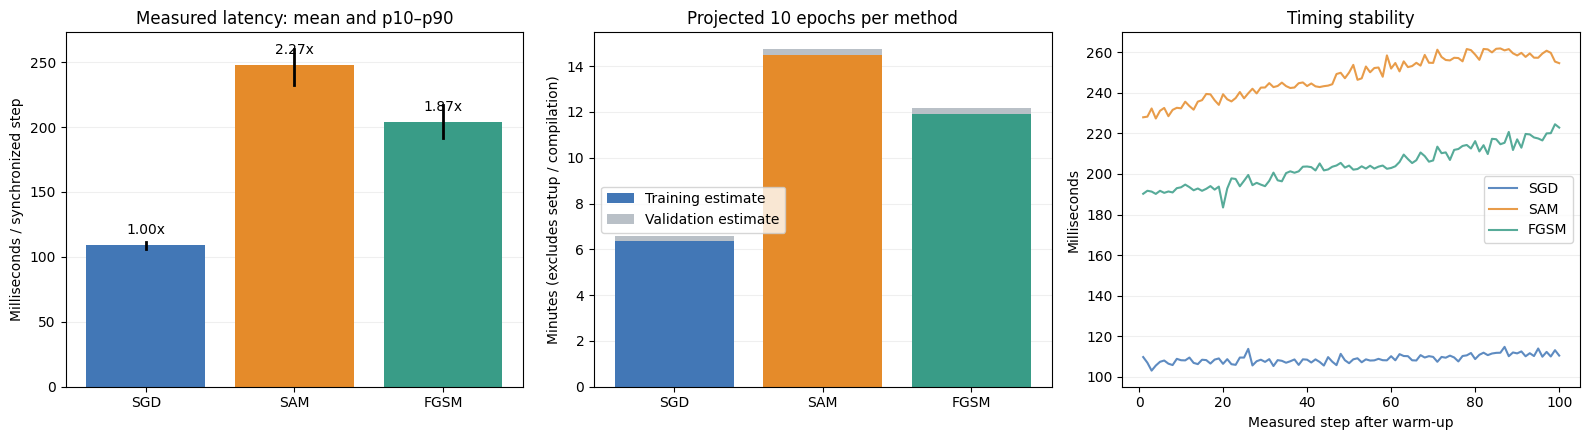

All three 10-epoch runs: estimated 33.5 minutes, plus compilation/setup and logging.
Use the stability plot to judge noise; p10–p90 describes steps, not uncertainty across independent runs.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ORDER = ['SGD','SAM','FGSM']
COLORS = ['#4277b6','#e58b2a','#399c87']
raw = json.loads((RUN/'benchmark.json').read_text())
bench = pd.DataFrame([{k:v for k,v in r.items() if k != 'step_seconds'} for r in raw]).set_index('method').loc[ORDER]
bench['slowdown_vs_sgd'] = bench.mean_ms / bench.loc['SGD','mean_ms']
bench.to_csv(RUN/'benchmark_summary.csv')
display(bench.round(3))
fig, axes = plt.subplots(1,3,figsize=(16,4.5))
axes[0].bar(ORDER,bench.mean_ms,color=COLORS)
for i,m in enumerate(ORDER):
    axes[0].plot([i,i],[bench.loc[m,'p10_ms'],bench.loc[m,'p90_ms']],color='black',lw=2)
    axes[0].annotate(f"{bench.loc[m,'slowdown_vs_sgd']:.2f}x",(i,bench.loc[m,'mean_ms']),xytext=(0,8),textcoords='offset points',ha='center')
axes[0].set(title='Measured latency: mean and p10–p90',ylabel='Milliseconds / synchronized step')
axes[1].bar(ORDER,bench.estimated_train_minutes,color=COLORS,label='Training estimate')
axes[1].bar(ORDER,bench.estimated_total_minutes-bench.estimated_train_minutes,bottom=bench.estimated_train_minutes,color='#b9c0c7',label='Validation estimate')
axes[1].set(title='Projected 10 epochs per method',ylabel='Minutes (excludes setup / compilation)'); axes[1].legend()
for m,c in zip(ORDER,COLORS):
    r = next(r for r in raw if r['method']==m)
    axes[2].plot(np.arange(1,len(r['step_seconds'])+1),1000*np.array(r['step_seconds']),label=m,color=c,alpha=.85)
axes[2].set(title='Timing stability',xlabel='Measured step after warm-up',ylabel='Milliseconds'); axes[2].legend()
for ax in axes: ax.grid(axis='y',alpha=.2); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RUN/'benchmark.png',dpi=180,bbox_inches='tight'); plt.show()
print(f"All three 10-epoch runs: estimated {bench.estimated_total_minutes.sum():.1f} minutes, plus compilation/setup and logging.")
print('Use the stability plot to judge noise; p10–p90 describes steps, not uncertainty across independent runs.')


In [7]:
RUN_PILOT = True  # Set True after reviewing the benchmark estimate.
if RUN_PILOT:
    rows=json.loads((RUN/'benchmark.json').read_text())
    projected=sum(r['estimated_total_minutes']*60+r['warmup_compile_seconds'] for r in rows)
    print('Projected pilot including warm-up:',round(projected/60,1),'minutes')
    if projected>CFG['budget_seconds']:
        print('Skipped: projected time exceeds the one-hour budget.')
    else:
        launch('pilot')
else:
    print('Pilot is off. Enable it to collect clean validation accuracy.')


Projected pilot including warm-up: 35.1 minutes
Running pilot in /content/runs/cifar10_resnet18_original_task/20261113_230318_00cfe6
2026-11-13 23:09:10.752810: W tensorflow/stream_executor/platform/default/dso_loader.cc:59] Could not load dynamic library 'libcudart.so.10.1'; dlerror: libcudart.so.10.1: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/envs/sam/lib:/usr/local/envs/sam/lib:/usr/local/lib:/usr/lib64-nvidia
2026-11-13 23:09:10.752867: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-11-13 23:09:12.058626: I tensorflow/stream_executor/platform/default/dso_loader.cc:48] Successfully opened dynamic library libcuda.so.1
2026-11-13 23:09:12.179493: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1716] Found device 0 with properties: 
pciBusID: 0000:00:04.0 name: Tesla T4 computeCapability: 7.5
coreClock: 1.59GHz coreCount: 40 deviceMemorySize: 14.56GiB 

Pilot status: {'status': 'complete', 'wall_seconds': 2111.8046242180003, 'gpu_hours': 0.5866123959188889}


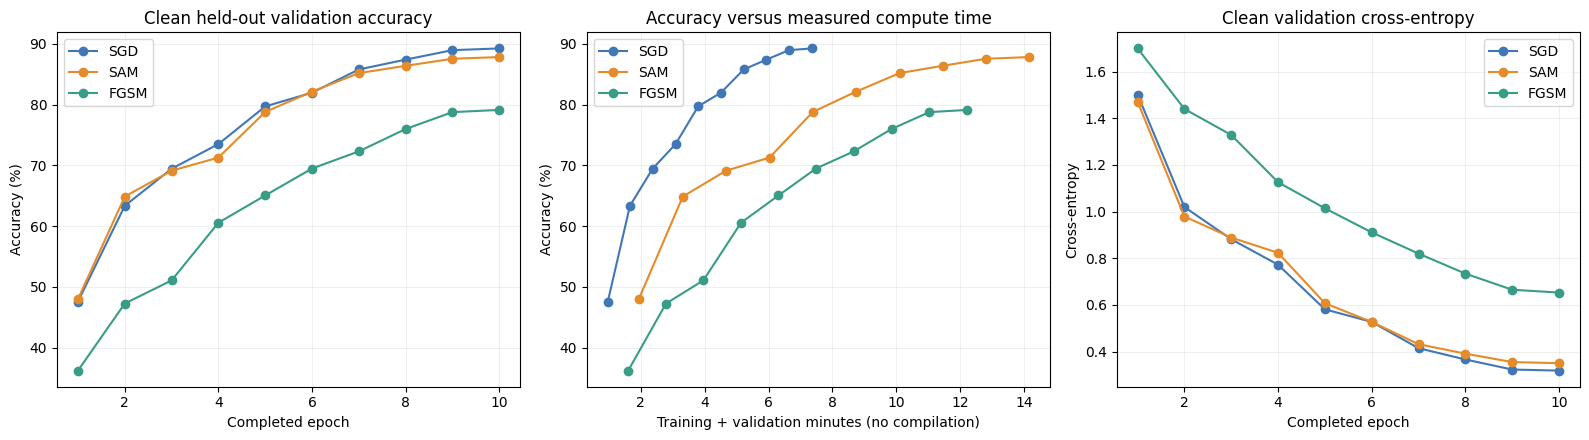

,epoch,train_seconds,eval_seconds,cumulative_train_seconds,cumulative_train_eval_seconds,last_lr,val_accuracy,val_loss,difference_vs_sgd_pp
method,,,,,,,,,
SGD,10,41.368,1.337,427.888,441.197,0.0,89.24,0.319,0.00
SAM,10,79.654,1.328,835.900,849.152,0.0,87.82,0.351,-1.42
FGSM,10,69.326,1.342,719.180,732.391,0.0,79.12,0.653,-10.12


Positive difference_vs_sgd_pp means higher final validation accuracy, in percentage points. One seed: no significance claim.


In [8]:
history_file = RUN/'pilot_history.json'
if history_file.exists():
    hist = pd.DataFrame(json.loads(history_file.read_text()))
    hist.to_csv(RUN/'pilot_history.csv',index=False)
    print('Pilot status:',json.loads((RUN/'pilot_status.json').read_text()))
    fig,axes = plt.subplots(1,3,figsize=(16,4.5))
    for m,c in zip(ORDER,COLORS):
        h = hist[hist.method==m]
        if h.empty: continue
        axes[0].plot(h.epoch,h.val_accuracy,'o-',label=m,color=c)
        axes[1].plot(h.cumulative_train_eval_seconds/60,h.val_accuracy,'o-',label=m,color=c)
        axes[2].plot(h.epoch,h.val_loss,'o-',label=m,color=c)
    axes[0].set(title='Clean held-out validation accuracy',xlabel='Completed epoch',ylabel='Accuracy (%)')
    axes[1].set(title='Accuracy versus measured compute time',xlabel='Training + validation minutes (no compilation)',ylabel='Accuracy (%)')
    axes[2].set(title='Clean validation cross-entropy',xlabel='Completed epoch',ylabel='Cross-entropy')
    for ax in axes: ax.grid(alpha=.2); ax.legend()
    fig.tight_layout(); fig.savefig(RUN/'pilot_curves.png',dpi=180,bbox_inches='tight'); plt.show()
    final = hist[hist.epoch==CFG['epochs']].set_index('method').copy()
    if not final.empty:
        if 'SGD' in final.index:
            final['difference_vs_sgd_pp'] = final.val_accuracy-final.loc['SGD','val_accuracy']
        final.to_csv(RUN/'final_epoch_summary.csv'); display(final.round(3))
    if len(final) != 3:
        print('Incomplete comparison: only methods with all 10 epochs appear in the final table.')
    print('Positive difference_vs_sgd_pp means higher final validation accuracy, in percentage points. One seed: no significance claim.')
else:
    print('No pilot accuracy data. Enable the optional pilot to populate these plots.')


Interpret the **final epoch-10** validation accuracy, not the best epoch. The comparison is exploratory: one seed, ten epochs, and equal epochs rather than equal compute. A positive SAM-minus-SGD difference is a gain in this run; a negative difference is also a valid result. Clean FGSM accuracy alone says nothing about adversarial robustness. The short-run result cannot establish the paper's causal explanation about flatness.


## 4. Save and share
Download the run folder before ending Colab. The ZIP includes the exact worker/configuration, GPU/environment information, split indices, raw timings, epoch results, CSV summaries, figures and logs. Failed or incomplete runs are retained. This notebook does not save model checkpoints or resume training.

For GitHub, keep the source notebook with outputs cleared and select small result summaries separately; do not commit the downloaded dataset, cloned repository, environment, or entire runtime folders. We will prepare the commit after reviewing this run.


In [9]:
archive_path=RUN.parent/(RUN.name+'.zip')
with zipfile.ZipFile(archive_path,'w',zipfile.ZIP_DEFLATED) as archive:
    for file in RUN.rglob('*'):
        if file.is_file(): archive.write(file,file.relative_to(RUN))
print('Saved run archive:',archive_path)
from google.colab import files
files.download(str(archive_path))


Saved run archive: /content/runs/cifar10_resnet18_original_task/20261113_230318_00cfe6.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>